In [1]:
import os
import zipfile
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory

In [2]:
from google.colab import files

uploaded = files.upload()

Saving dataset_4.zip to dataset_4.zip


In [3]:
zip_path = "dataset_4.zip"
extract_path = "dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [4]:
print(os.listdir(extract_path))

['RedRot', 'Rust', 'Yellow', 'Healthy', 'Mosaic']


In [5]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

train_dataset = image_dataset_from_directory(
    extract_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

validation_dataset = image_dataset_from_directory(
    extract_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names

print("Classes:")
print(class_names)

num_classes = len(class_names)

Found 2521 files belonging to 5 classes.
Using 2017 files for training.
Found 2521 files belonging to 5 classes.
Using 504 files for validation.
Classes:
['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)

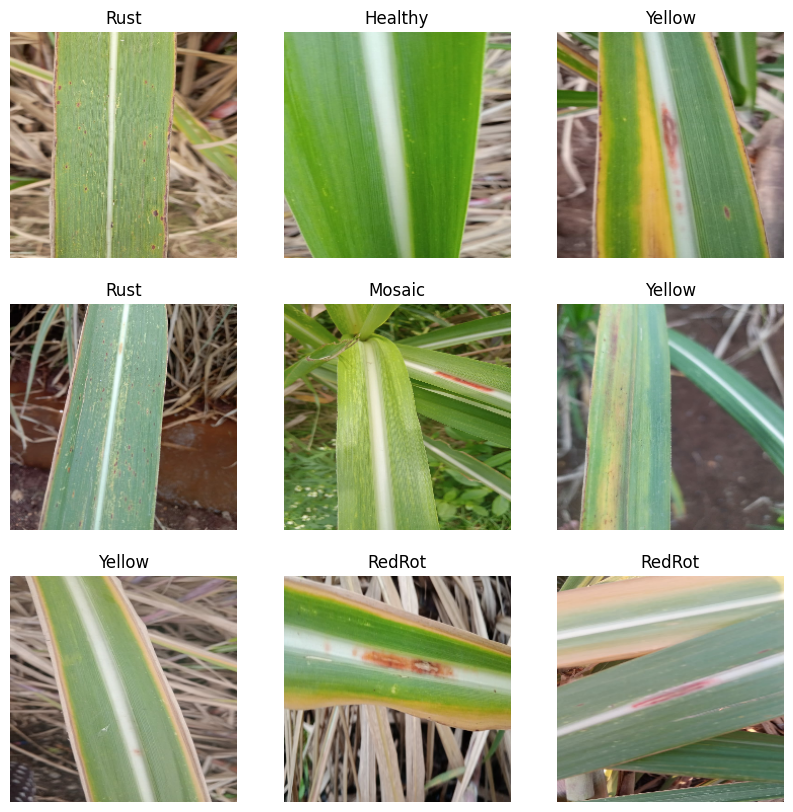

In [7]:
plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.show()

In [8]:
model = models.Sequential([

    layers.Rescaling(1./255, input_shape=(224,224,3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')

])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,605 (42.61 MB)

 Trainable params: 11,169,605 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 156s 2s/step - accuracy: 0.3257 - loss: 1.5047 - val_accuracy: 0.4960 - val_loss: 1.3038
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 184s 2s/step - accuracy: 0.4779 - loss: 1.2575 - val_accuracy: 0.5556 - val_loss: 1.1424
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.6098 - loss: 1.0120 - val_accuracy: 0.5992 - val_loss: 0.9672
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.7070 - loss: 0.7604 - val_accuracy: 0.7083 - val_loss: 0.7863
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.7923 - loss: 0.5517 - val_accuracy: 0.7500 - val_loss: 0.6811
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.8666 - loss: 0.3827 - val_accuracy: 0.7619 - val_loss: 0.7334
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.8919 - loss: 0.2924 - val_accuracy: 0.7758 - val_loss: 0.7201
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.9227 - loss: 0.2186 - val_accuracy: 0.7679 - v

In [11]:
loss, accuracy = model.evaluate(validation_dataset)

print("Validation Loss :", loss)
print("Validation Accuracy :", accuracy)

16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 586ms/step - accuracy: 0.7758 - loss: 0.7646
Validation Loss : 0.7646470069885254
Validation Accuracy : 0.7757936716079712


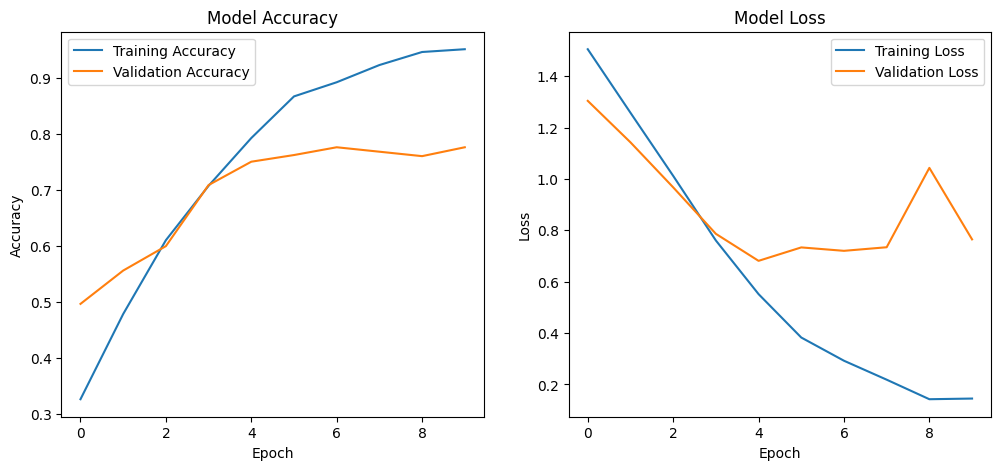

In [12]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [13]:
model.save("tomato_disease_cnn_model.h5")

print("Model Saved Successfully!")

Model Saved Successfully!


In [14]:
from google.colab import files

uploaded = files.upload()

Saving sample.jpg to sample.jpg


In [15]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "sample.jpg"

img = image.load_img(img_path, target_size=(224,224))

img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = class_names[np.argmax(prediction)]

confidence = np.max(prediction)

print("Predicted Disease :", predicted_class)

print("Confidence :", confidence * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
Predicted Disease : Rust
Confidence : 99.950615 %
